# Retail Sales Data Analysis
**Name:** Yasmeen Akhter  
**Project:** Level 1, Task 1 (Oasis Infobyte Internship)

### Introduction
In this notebook I do an Exploratory Data Analysis (EDA) on a retail sales dataset. I look at sales over time, customer age and gender, product categories, and how the numbers relate to each other. At the end I give some business suggestions.

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# show charts inside the notebook
%matplotlib inline

# chart style
sns.set_theme(style="ticks")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
# load the dataset
sales_data = pd.read_csv('retail_sales_dataset.csv')

# shape of the data
print("Rows and columns:", sales_data.shape)

# data types of each column
print("\nData types:")
print(sales_data.dtypes)

# check missing values
print("\nMissing values:")
print(sales_data.isnull().sum())

Rows and columns: (1000, 9)

Data types:
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


### Observations
* The dataset has **1000 rows** and **9 columns**.
* There are **no missing values**, so I do not need to clean or fill anything.
* The columns include date, customer ID, gender, age, product category, quantity, price per unit and total amount.

In [3]:
# numerical columns
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

# mean, std, min, median (50%), max
print("Summary statistics:")
print(sales_data[num_cols].describe())

# mode (most common value)
print("\nMode:")
print(sales_data[num_cols].mode().iloc[0])

Summary statistics:
              Age     Quantity  Price per Unit  Total Amount
count  1000.00000  1000.000000     1000.000000   1000.000000
mean     41.39200     2.514000      179.890000    456.000000
std      13.68143     1.132734      189.681356    559.997632
min      18.00000     1.000000       25.000000     25.000000
25%      29.00000     1.000000       30.000000     60.000000
50%      42.00000     3.000000       50.000000    135.000000
75%      53.00000     4.000000      300.000000    900.000000
max      64.00000     4.000000      500.000000   2000.000000

Mode:
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64


### Observations
* **Age:** The average age is about **41.4** years. The median is 42 and the most common age is 43. The standard deviation is about 13.7, so customers are spread across many ages (18 to 64).
* **Quantity:** The average quantity is about **2.5** units per order. The median is 3 and the most common quantity is 4.
* **Price per Unit:** The average price is **$179.89**, but the standard deviation is high (about 189.7). This means the store sells both cheap and expensive items.
* **Total Amount:** The average order is **$456**. The standard deviation is about 560, so some orders are much bigger than others.

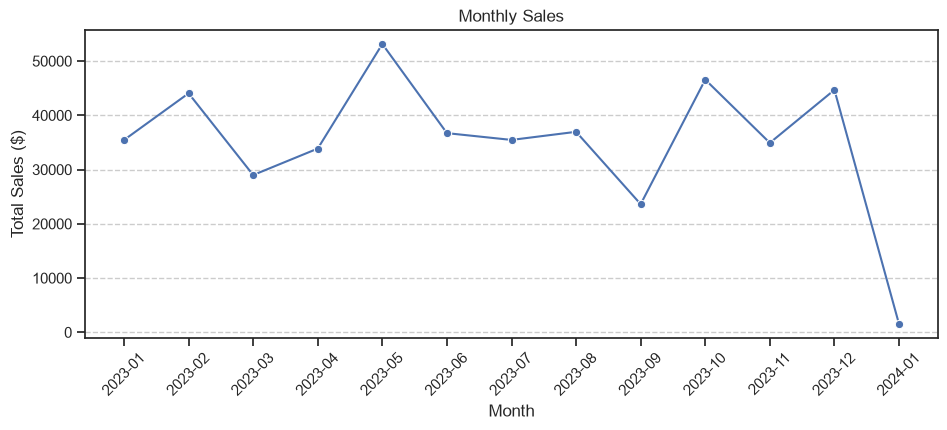

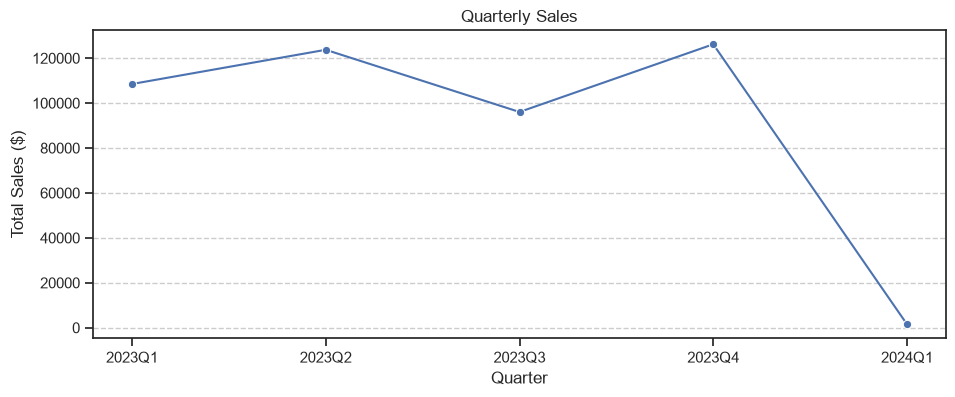

      Month  Total Amount
0   2023-01         35450
1   2023-02         44060
2   2023-03         28990
3   2023-04         33870
4   2023-05         53150
5   2023-06         36715
6   2023-07         35465
7   2023-08         36960
8   2023-09         23620
9   2023-10         46580
10  2023-11         34920
11  2023-12         44690
12  2024-01          1530
  Quarter  Total Amount
0  2023Q1        108500
1  2023Q2        123735
2  2023Q3         96045
3  2023Q4        126190
4  2024Q1          1530


In [4]:
# convert Date to datetime
sales_data['Date'] = pd.to_datetime(sales_data['Date'])

# make month and quarter columns
sales_data['Month'] = sales_data['Date'].dt.to_period('M').astype(str)
sales_data['Quarter'] = sales_data['Date'].dt.to_period('Q').astype(str)

# total sales for each month and quarter
monthly_sales = sales_data.groupby('Month')['Total Amount'].sum().reset_index()
quarterly_sales = sales_data.groupby('Quarter')['Total Amount'].sum().reset_index()

# monthly line chart
plt.figure(figsize=(11, 4))
sns.lineplot(data=monthly_sales, x='Month', y='Total Amount',marker='o')
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.show()

# quarterly line chart
plt.figure(figsize=(11, 4))
sns.lineplot(data=quarterly_sales, x='Quarter', y='Total Amount', marker='o')
plt.title('Quarterly Sales')
plt.xlabel('Quarter')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', linestyle='--')
plt.show()

# print the numbers to use in observations
print(monthly_sales)
print(quarterly_sales)

### Observations
* **Monthly:** May 2023 has the highest sales (about $53,000). September 2023 is the lowest full month (about $24,000). October and December are also strong months.
* The last point (January 2024) is very low because the data has only a small part of that month. It is not a real drop in sales.
* **Quarterly:** The highest quarter is 2023 Q4 (about $126,000) and the lowest quarter is 2023 Q3 (about $96,000). The 2024 Q1 point is very small because the data has only a little of January 2024.
* Sales go up and down through the year, so the store should plan stock for busy months.

Gender
Female    510
Male      490
Name: count, dtype: int64
Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195
Name: count, dtype: int64


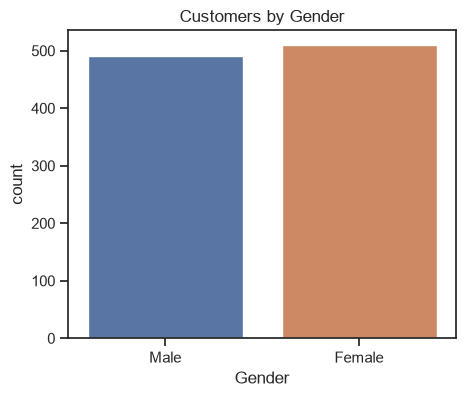

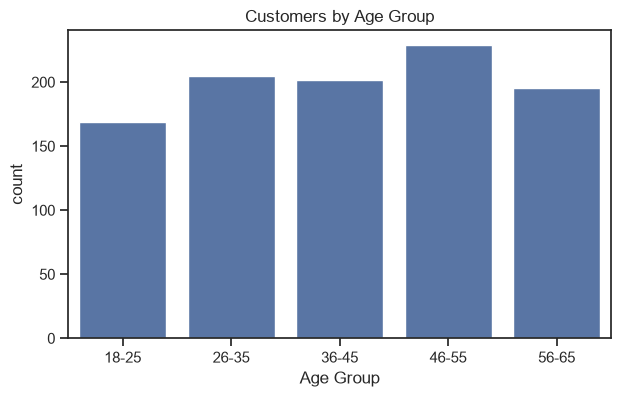

In [5]:
# gender count
print(sales_data['Gender'].value_counts())

# make age groups
sales_data['Age Group'] = pd.cut(sales_data['Age'],
                                 bins=[17, 25, 35, 45, 55, 65],
                                 labels=['18-25', '26-35', '36-45', '46-55', '56-65'])
print(sales_data['Age Group'].value_counts().sort_index())

# gender chart
plt.figure(figsize=(5, 4))
sns.countplot(data=sales_data, x='Gender', hue='Gender')
plt.title('Customers by Gender')
plt.show()

# age group chart
plt.figure(figsize=(7, 4))
sns.countplot(data=sales_data, x='Age Group', order=['18-25', '26-35', '36-45', '46-55', '56-65'])
plt.title('Customers by Age Group')
plt.show()

### Observations
* Gender: There are 510 female customers and 490 male customers. The split is almost equal.
* Age groups: The group 46-55 has the most customers (229) and the group 18-25 has the fewest (169).
* Customers come from all age groups, so the store does not depend on only one age group.

  Product Category  Total Amount
0      Electronics        156905
1         Clothing        155580
2           Beauty        143515


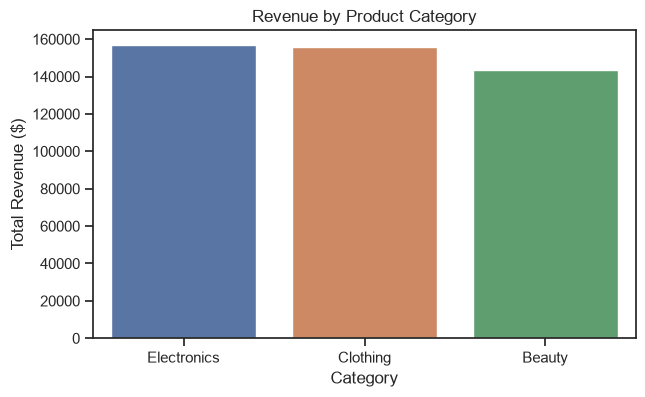

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


In [6]:
# total revenue by category
category_revenue = sales_data.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False).reset_index()
print(category_revenue)

# bar chart of revenue by category
plt.figure(figsize=(7, 4))
sns.barplot(data=category_revenue, x='Product Category', y='Total Amount', hue='Product Category')
plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Revenue ($)')
plt.show()

# best selling categories by quantity sold
category_quantity = sales_data.groupby('Product Category')['Quantity'].sum().sort_values(ascending=False)
print(category_quantity)

### Observations
* Electronics earns the most revenue (about $157,000). Clothing is almost the same (about $156,000). Beauty is the lowest (about $144,000).
* The three categories are close to each other, so no single category is far ahead.
* This dataset has only 3 product categories and no product names, so I cannot make a "top 10 products" list. I ranked the categories by quantity sold.
* By quantity sold, Clothing is first (894), Electronics is second (849) and Beauty is third (771).

                     Age  Quantity  Price per Unit  Total Amount
Age             1.000000 -0.023737       -0.038423     -0.060568
Quantity       -0.023737  1.000000        0.017501      0.373707
Price per Unit -0.038423  0.017501        1.000000      0.851925
Total Amount   -0.060568  0.373707        0.851925      1.000000


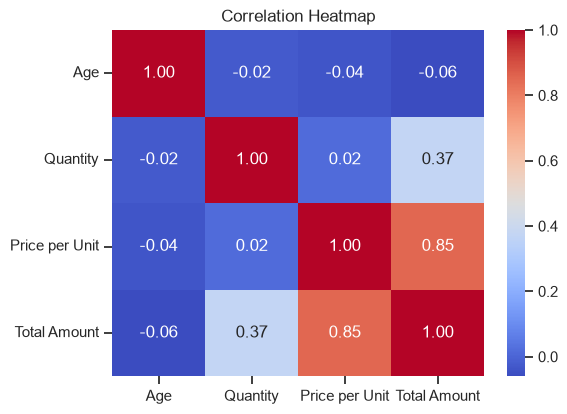

In [7]:
# correlation between numerical columns
corr = sales_data[num_cols].corr()
print(corr)

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

### Observations
* Total Amount is strongly related to Price per Unit (correlation 0.85) and moderately related to Quantity (correlation 0.37). This makes sense because Total Amount = Quantity x Price per Unit.
* Age has almost no relation with the other columns (values between -0.02 and -0.06). So age does not decide how much a customer spends.

  Age Group  Total Amount
0     18-25    500.295858
1     26-35    480.390244
2     36-45    454.801980
3     46-55    439.694323
4     56-65    412.358974


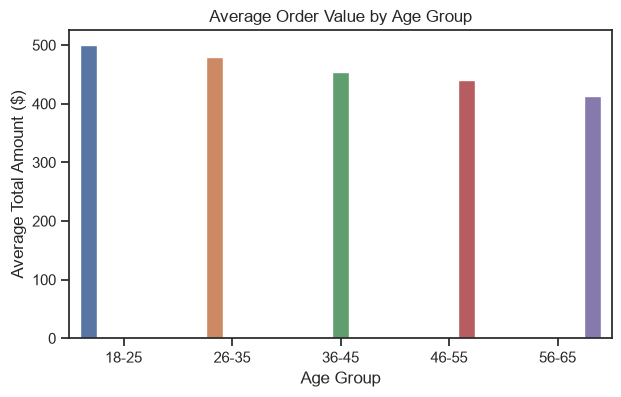

In [8]:
# average order value for each age group
avg_by_age = sales_data.groupby('Age Group', observed=True)['Total Amount'].mean().reset_index()
print(avg_by_age)

plt.figure(figsize=(7, 4))
sns.barplot(data=avg_by_age, x='Age Group', y='Total Amount', hue='Age Group', legend=False)
plt.title('Average Order Value by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Total Amount ($)')
plt.show()

### Observations
* The age group 18-25 spends the most per order (about $500), and 56-65 spends the least (about $412).
* The group with the most customers (46-55) spends only about $440 per order, which is lower than the 18-25 group. So the biggest group of customers is not the group that spends the most.

## Conclusion and Recommendations

**Main findings:** The store has 1000 orders with no missing data. Sales are highest in May and lowest in September. Electronics and Clothing earn almost the same revenue, and Beauty earns the least.

**Recommendations:**
1. **Stock up before busy months.** May, October and December have the highest sales, so the store should keep more stock and run ads before these months. September is the slowest month, so offers or discounts can help.
2. **Promote Beauty products.** Beauty earns the least revenue (about $144,000). A discount or a bundle with Clothing can help it catch up.
3. **Target young customers with offers.** The 18-25 age group spends the most per order (about $500), so marketing and special offers should focus on them. The 56 - 65 age group spends the least (about $412), so offers on bigger bundles can help increase their spending.